In [15]:
import sys
import torch
import tabulate
import numpy as np
import pandas as pd
import torch.nn as nn
from pathlib import Path
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent/"src"))
from features import add_geometry_features
from evaluation import add_results, plot_pred_vs_true
import models

results = {}

# Evaluation
So far we have tested the models on the `full` set, however we have not tested our models on conditions where they have not been trained (extrapolation). Therefore the goal of this notebook is to train every model again on the different data splits and comparing the results.

In [16]:
# Figure saving
FIG_DIR = Path().resolve().parent / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Load and Prepare the Data into a dataframe
CSV_PATH = Path().resolve().parent/"data"/"processed"/"airfrans_coefficients.csv"
df = pd.read_csv(CSV_PATH)
df = add_geometry_features(df)
df["Re_millions"] = df["Re"] / 1e6 
df["aoa2"] = df["angleOfAttack"] ** 2

df.head()


,name,inletVelocity,Re,angleOfAttack,M,L,P,Q,XX,cl,...,split_full,split_scarce,split_reynolds,split_aoa,max_camber,camber_pos,thickness,reflex,Re_millions,aoa2
0,airFoil2D_SST_36.622_11.319_3.941_5.424_1.0_16...,36.622,2.347564e+06,11.319,NaN,3.941,5.424,True,16.283,1.388165,...,train,train,test,train,0.045809,0.2710,0.16283,1,2.347564,128.119761
1,airFoil2D_SST_58.831_-3.563_2.815_4.916_10.078,58.831,3.771218e+06,-3.563,2.815,NaN,4.916,NaN,10.078,-0.061631,...,train,train,train,test,0.028150,0.4916,0.10078,0,3.771218,12.694969
2,airFoil2D_SST_43.327_8.905_4.236_6.511_10.744,43.327,2.777372e+06,8.905,4.236,NaN,6.511,NaN,10.744,1.435620,...,train,train,test,train,0.042360,0.6511,0.10744,0,2.777372,79.299025
3,airFoil2D_SST_89.151_4.462_0.974_4.094_1.0_19.856,89.151,5.714808e+06,4.462,NaN,0.974,4.094,True,19.856,0.516280,...,train,train,test,train,0.010223,0.2050,0.19856,1,5.714808,19.909444
4,airFoil2D_SST_87.422_2.992_1.895_3.128_1.0_10.656,87.422,5.603974e+06,2.992,NaN,1.895,3.128,True,10.656,0.452903,...,train,train,test,train,0.017751,0.1560,0.10656,1,5.603974,8.952064


In [17]:
MEAN_FEATURES = []
AOA2_FEATURES = ["angleOfAttack","Re_millions","max_camber","camber_pos","thickness","reflex","aoa2"]
TREE_FEATURES = ["angleOfAttack","Re","max_camber","camber_pos","thickness","reflex"]
MLP_FEATURES = ["angleOfAttack","Re","max_camber","camber_pos","thickness","reflex"]

MODELS = {
    "mean_baseline":     (models.fit_predict_mean,MEAN_FEATURES,["cl","cd"]),
    "thin_airfoil":      (models.fit_predict_thin_airfoil,["angleOfAttack"],["cl"]),
    "linear_aoa2":       (models.fit_predict_linear,AOA2_FEATURES,["cl","cd"]),
    "gradient_boosting": (models.fit_predict_gb,TREE_FEATURES,["cl","cd"]),
    "mlp":               (models.fit_predict_mlp,MLP_FEATURES,["cl","cd"]),
}
results = {}
predictions = {}


In [18]:
# Main Loop
for split in ["full","scarce","reynolds","aoa"]:
    train = df.loc[df[f"split_{split}"]=="train"]
    test = df.loc[df[f"split_{split}"]=="test"]

    for name, (fit_predict,features,targets) in MODELS.items():
        pred = fit_predict(train[features],train[targets],test[features])
        predictions[(split,name)] = pred
        kwargs = {"output":False}
        for target in targets:
            kwargs[f"{target}_true"] = test[target]
            kwargs[f"{target}_pred"] = pred[target]
        results = add_results(results, f"{name}_{split}", **kwargs)

print(pd.DataFrame(predictions[("aoa","mlp")]))


           cl        cd
0   -0.102087  0.008333
1   -0.294386  0.008250
2    1.435254  0.020688
3   -0.204523  0.009421
4   -0.085877  0.008710
..        ...       ...
191  0.093382  0.010590
192 -0.169014  0.008180
193  0.465532  0.008888
194  1.599145  0.023450
195 -0.352560  0.009853

[196 rows x 2 columns]


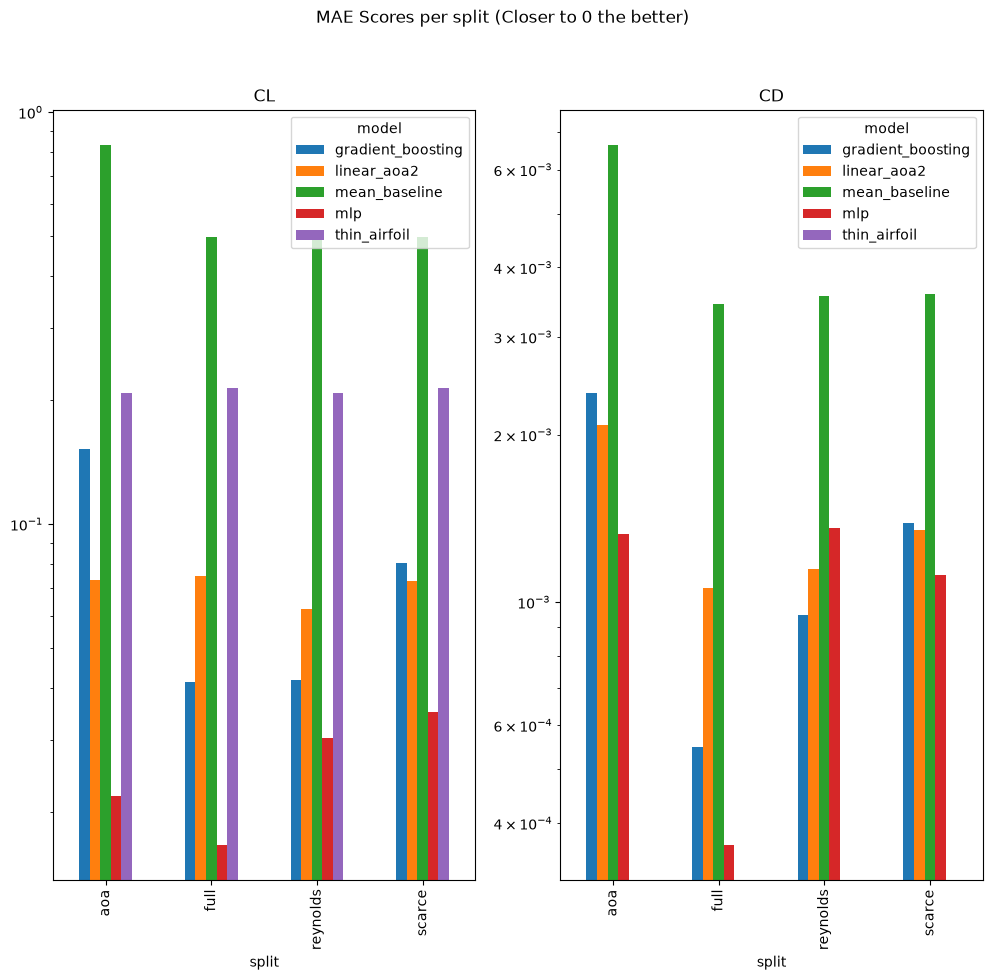

In [19]:
# Plotting MAE results
fig, ax = plt.subplots(1,2,figsize=(12,10))


table = pd.DataFrame(results).T
table[["model","split"]] = table.index.str.rsplit("_",n=1).tolist()
cl_mae = table.pivot(index="split", columns="model", values="cl_mae")
cd_mae = table.pivot(index="split",columns="model",values="cd_mae")
cl_mae.plot.bar(ax=ax[0],logy=True)
cd_mae.plot.bar(ax=ax[1],logy=True)

fig.suptitle("MAE Scores per split (Closer to 0 the better)")

ax[0].set_title("CL")
ax[1].set_title("CD")

# save fig as png
fig.savefig(FIG_DIR / "mae_by_split.png", dpi=150, bbox_inches="tight")
plt.show()

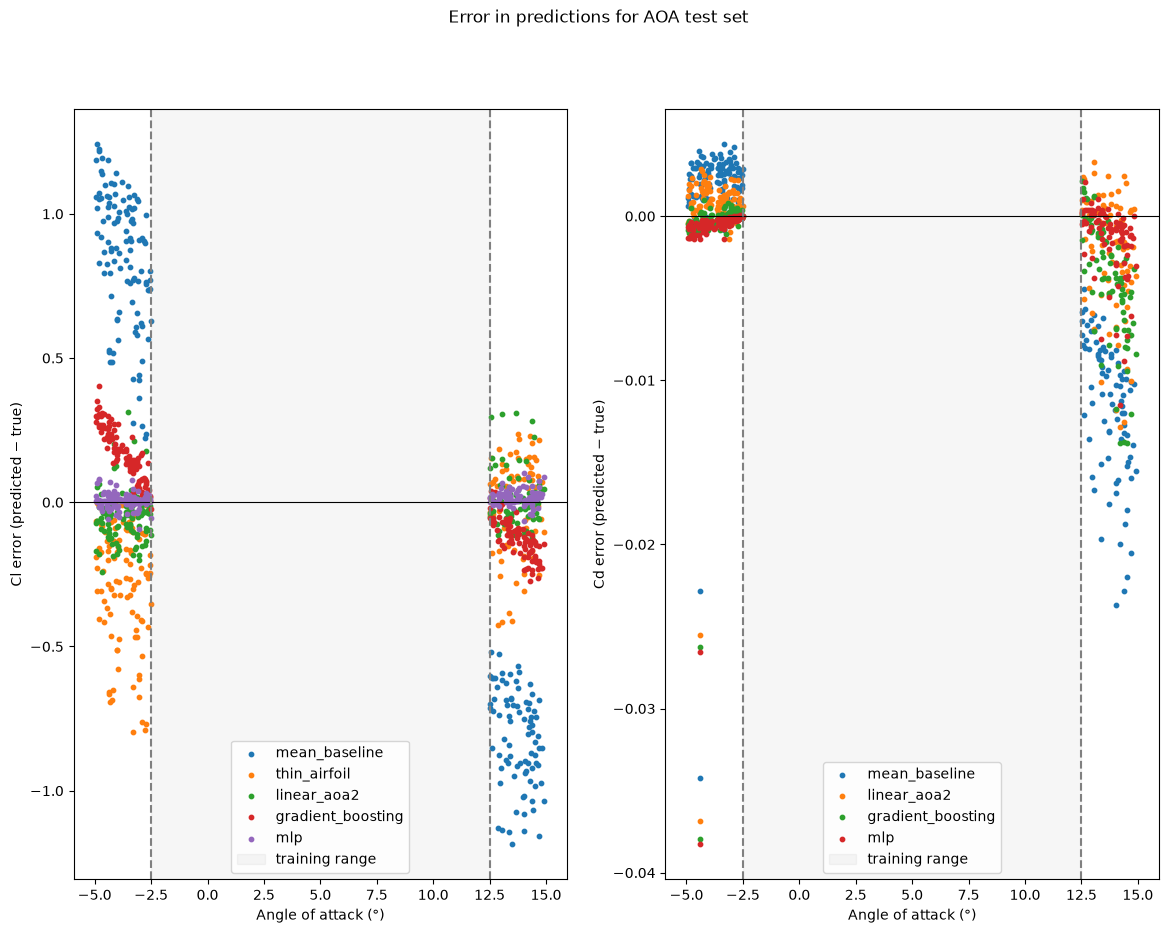

In [20]:
# Plotting the predictions
fig,ax = plt.subplots(1,2, figsize=(14,10))
test = df.loc[df["split_aoa"] == "test"]


for name in MODELS:
    points = predictions[("aoa",name)]
    for i, target in enumerate(["cl","cd"]):
        if points.get(target) is None:
            continue;
        error = points[target] - test[target]
        ax[i].scatter(test["angleOfAttack"],error,s=10,label=name)


for i, target in enumerate(["Cl", "Cd"]):
    # perfect prediction
    ax[i].axhline(0, color="black", linewidth=0.8)

    # Edges of the training set 
    ax[i].axvline(-2.5, linestyle="--", color="grey")    
    ax[i].axvline(12.5, linestyle="--", color="grey")

    ax[i].set_xlabel("Angle of attack (°)")
    ax[i].set_ylabel(f"{target} error (predicted − true)")
    ax[i].axvspan(-2.5, 12.5, color="darkgrey", alpha=0.1, label="training range")


fig.suptitle("Error in predictions for AOA test set")
ax[0].legend()
ax[1].legend()
plt.show()

# save fig as png
fig.savefig(FIG_DIR / "aoa_error.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
pred = predictions[("aoa", "mlp")]["cd"]
check = test[["name", "angleOfAttack", "thickness", "cd"]].copy()
check["pred"] = pred
check["error"] = check["pred"] - check["cd"]
print(check.sort_values("error").head(5))

                                                  name  angleOfAttack  \
171  airFoil2D_SST_50.077_-4.416_2.834_4.029_1.0_5.156         -4.416   
554  airFoil2D_SST_37.191_-4.384_1.742_3.249_0.0_5.697         -4.384   
282   airFoil2D_SST_87.75_14.191_0.722_3.837_1.0_6.198         14.191   
537  airFoil2D_SST_34.136_14.393_2.103_3.685_0.0_6.065         14.393   
101      airFoil2D_SST_36.716_13.365_2.832_4.656_6.353         13.365   

     thickness        cd      pred     error  
171    0.05156  0.045949  0.007667 -0.038282  
554    0.05697  0.034604  0.008057 -0.026548  
282    0.06198  0.031691  0.020173 -0.011518  
537    0.06065  0.034586  0.025789 -0.008797  
101    0.06353  0.031422  0.023922 -0.007500  


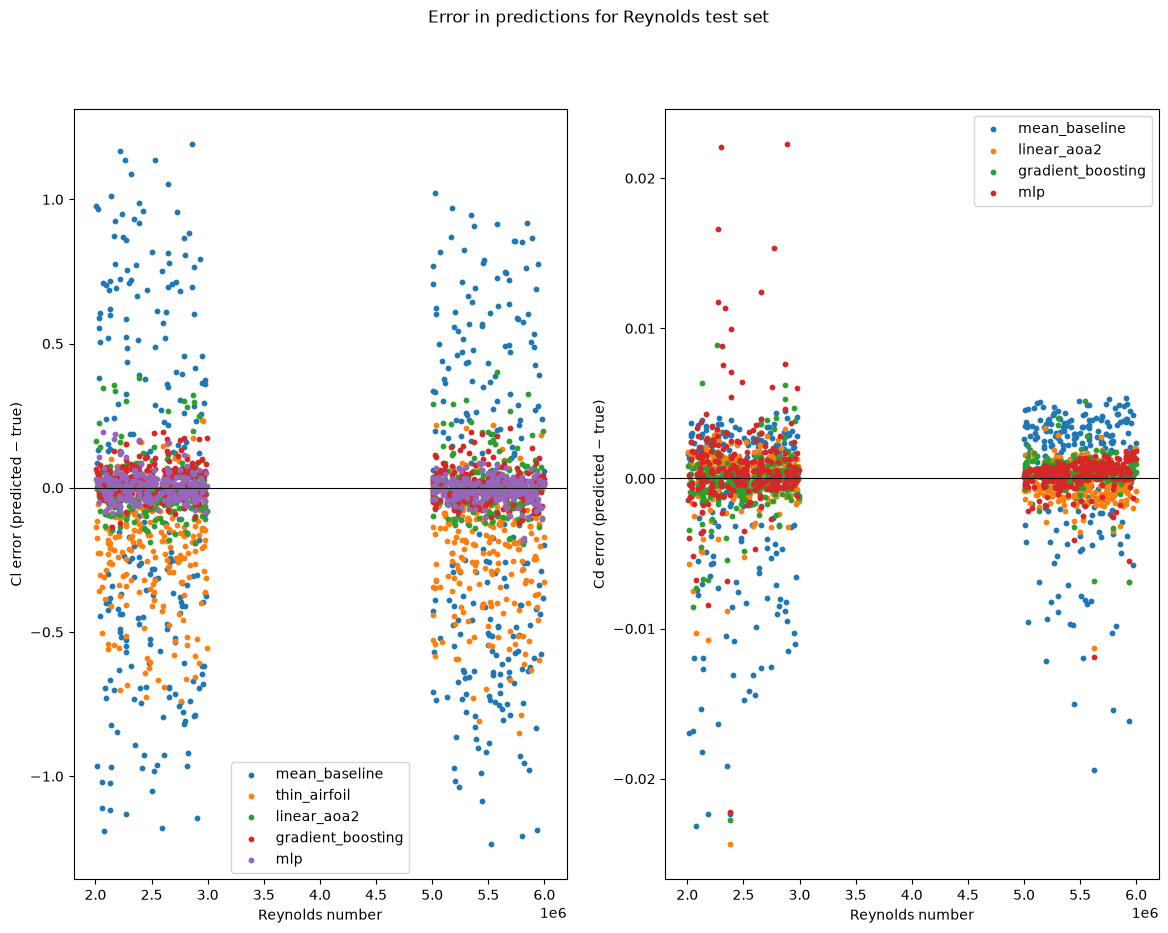

In [22]:
# Plotting the predictions
fig,ax = plt.subplots(1,2, figsize=(14,10))
test = df.loc[df["split_reynolds"] == "test"]


for name in MODELS:
    points = predictions[("reynolds",name)]
    for i, target in enumerate(["cl","cd"]):
        if points.get(target) is None:
            continue;
        error = points[target] - test[target]
        ax[i].scatter(test["Re"],error,s=10,label=name)


for i, target in enumerate(["Cl", "Cd"]):
    # perfect prediction
    ax[i].axhline(0, color="black", linewidth=0.8)

    # Edges of the training set 

    ax[i].set_xlabel("Reynolds number")
    ax[i].set_ylabel(f"{target} error (predicted − true)")


fig.suptitle("Error in predictions for Reynolds test set")
ax[0].legend()
ax[1].legend()
plt.show()

# save fig as png
fig.savefig(FIG_DIR / "reynolds_error.png", dpi=150, bbox_inches="tight")
plt.show()

From the above graph, The particuarly interesting finding is for the coefficient of drag and at low RE values, the MLP appears to be wildly inaccurate, with a large number of overestimations. so as a quick investigation, I will attempt to train a model using `log(Re)` instead of `Re` to see if the overprediction at low Re numbers reduces

In [23]:
# Create the log(Re) feature
df["log(Re)"] = np.log(df["Re"])
MLP_LOG_FEATURES = ["angleOfAttack","log(Re)","max_camber","camber_pos","thickness","reflex"]
targets = ["cl","cd"]
df.head()



for split in ["reynolds", "full"]:
    train = df.loc[df[f"split_{split}"]=="train"]
    test = df.loc[df[f"split_{split}"]=="test"]
    # predict
    pred = models.fit_predict_mlp(train[MLP_LOG_FEATURES],train[["cl","cd"]],test[MLP_LOG_FEATURES])
    predictions[(split,"mlp_logRe")] = pred
    # add to results
    kwargs = {"output":False}
    for target in targets:
        kwargs[f"{target}_true"] = test[target]
        kwargs[f"{target}_pred"] = pred[target]
    results = add_results(results, f"mlp_logRe_{split}", **kwargs)

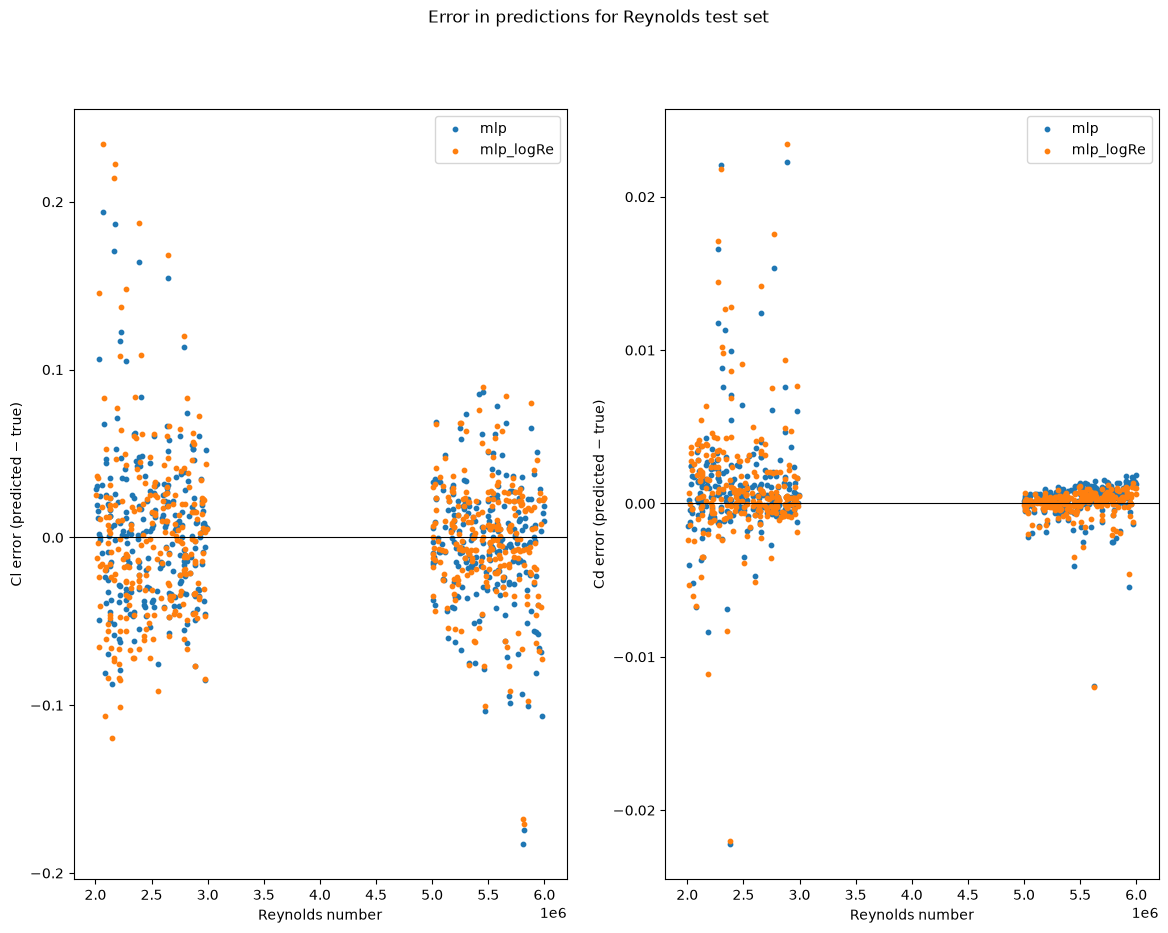

In [24]:
# Plotting the predictions
fig,ax = plt.subplots(1,2, figsize=(14,10))
test = df.loc[df["split_reynolds"] == "test"]


for name in ["mlp","mlp_logRe"]:
    points = predictions[("reynolds",name)]
    for i, target in enumerate(["cl","cd"]):
        if points.get(target) is None:
            continue;
        error = points[target] - test[target]
        ax[i].scatter(test["Re"],error,s=10,label=name)


for i, target in enumerate(["Cl", "Cd"]):
    # perfect prediction
    ax[i].axhline(0, color="black", linewidth=0.8)

    # Edges of the training set 

    ax[i].set_xlabel("Reynolds number")
    ax[i].set_ylabel(f"{target} error (predicted − true)")


fig.suptitle("Error in predictions for Reynolds test set")
ax[0].legend()
ax[1].legend()
plt.show()

From the above graph, intial results are the mlp_logRe performs worse than the normal Re due to the wider spread of all CLs and the lower RE values for CD. At higher Re values, the CD prediction actually appears much more accurate with a lower error spread

Text(0, 0.5, 'MAE score')

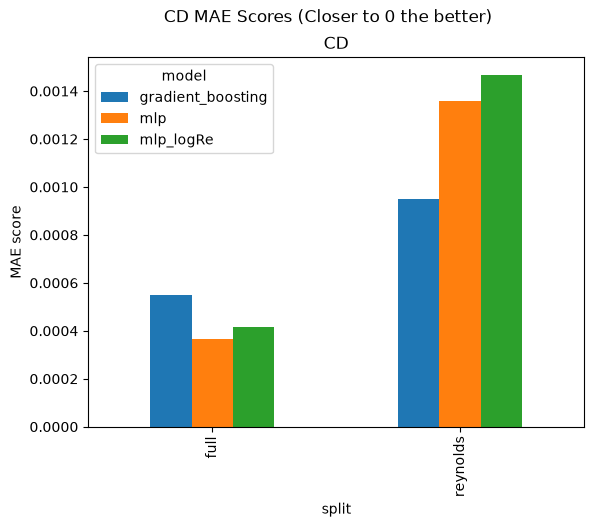

In [25]:
# Printing MAE values for the cd values
# Plotting MAE results
fig, ax = plt.subplots()


table = pd.DataFrame(results).T
table[["model","split"]] = table.index.str.rsplit("_",n=1).tolist()
cd_mae = table.pivot(index="split",columns="model",values="cd_mae")

compare = cd_mae.loc[["full","reynolds"],["gradient_boosting","mlp","mlp_logRe"]]

compare.plot.bar(ax=ax,logy=False)
fig.suptitle("CD MAE Scores (Closer to 0 the better)")
ax.set_title("CD")
ax.set_ylabel("MAE score")

So under Reynold-number extrapolation, gradient boosing is the best CD model and the mlp's CD error grows by ~3.7 times whereas gradient boosing's was ~1.7. Rescalling Re to log(Re) made the mlp perform worse for both the full and reynolds splits. 

In [26]:
# Store the results as csv
RESULTS_PATH = Path().resolve().parent/"results"/"split_metrics.csv"
COLUMNS = ["model","cl_mae","cl_rmse","cl_r2","cd_mae","cd_rmse","cd_r2"]

results_df = (
    pd.DataFrame.from_dict(results, orient="index")
      .rename_axis("model")
      .reset_index()
)[COLUMNS]
results_df.to_csv(RESULTS_PATH, index=False)

---
# README tables

In [29]:
# --- README tables ---
metrics = pd.read_csv(Path().resolve().parent / "results" / "split_metrics.csv")
metrics[["model", "split"]] = metrics["model"].str.rsplit("_", n=1).tolist()
main = metrics[metrics["model"] != "mlp_logRe"]
full = main[main["split"] == "full"]

print(full[["model", "cl_r2", "cl_mae", "cd_r2", "cd_mae"]].round(5).to_markdown(index=False))

grid = main.pivot(index="model", columns="split", values="cl_mae")[["full", "scarce", "reynolds", "aoa"]]


print(grid.round(5).to_markdown())

| model             |    cl_r2 |   cl_mae |     cd_r2 |    cd_mae |
|:------------------|---------:|---------:|----------:|----------:|
| mean_baseline     | -0.00201 |  0.49825 |  -0.0011  |   0.00343 |
| thin_airfoil      |  0.74281 |  0.21423 | nan       | nan       |
| linear_aoa2       |  0.96762 |  0.07477 |   0.9041  |   0.00106 |
| gradient_boosting |  0.99018 |  0.04137 |   0.96523 |   0.00055 |
| mlp               |  0.99843 |  0.01667 |   0.98047 |   0.00037 |
| model             |    full |   scarce |   reynolds |     aoa |
|:------------------|--------:|---------:|-----------:|--------:|
| gradient_boosting | 0.04137 |  0.08053 |    0.04181 | 0.15244 |
| linear_aoa2       | 0.07477 |  0.0726  |    0.06226 | 0.07325 |
| mean_baseline     | 0.49825 |  0.49753 |    0.49553 | 0.83346 |
| mlp               | 0.01667 |  0.03491 |    0.0302  | 0.02192 |
| thin_airfoil      | 0.21423 |  0.21423 |    0.20767 | 0.20812 |
